In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter
from openpyxl.chart import BarChart, Reference

# Set plotting style
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

class SimuladorBancoColombia:
    def __init__(self, horas_operacion=8):
        self.tiempo_simulacion = horas_operacion * 60  # 480 minutos
        self.prob_retiro = 0.70
        self.prob_pago = 0.30

        self.tipos_usuario = ['Rápido', 'Normal', 'Lento', 'Muy lento']
        self.prob_usuario = {
            'Retiro': [0.23, 0.40, 0.17, 0.20],
            'Pago':   [0.10, 0.20, 0.30, 0.40]
        }
        self.media_servicio = {
            'Retiro': [1.0, 2.0, 3.0, 4.0],
            'Pago':   [3.0, 3.0, 5.0, 7.0]
        }
        self.media_llegada = {
            'Retiro': [1.0, 2.0, 3.0, 3.0],
            'Pago':   [1.0, 2.0, 3.0, 4.0]
        }

    def generar_llegadas_dia(self, rng):
        """Genera la secuencia de llegadas de clientes durante 8 horas (480 min)."""
        llegadas = []
        t = 0.0
        while True:
            accion = 'Retiro' if rng.random() < self.prob_retiro else 'Pago'
            u_idx = rng.choice(4, p=self.prob_usuario[accion])
            dt = rng.exponential(self.media_llegada[accion][u_idx])
            t += dt
            if t > self.tiempo_simulacion:
                break
            ts = rng.exponential(self.media_servicio[accion][u_idx])
            llegadas.append({
                'tiempo_llegada': t,
                'tipo_accion': accion,
                'tipo_usuario': self.tipos_usuario[u_idx],
                'tiempo_servicio': ts
            })
        return llegadas

    def simular_escenario(self, llegadas, configuracion):
        """
        Simula cajeros independientes M/M/1 con disciplina FIFO.
        configuracion: lista de tipos permitidos por cajero, ej:
          - ['Mixto', 'Mixto', 'Mixto']
          - ['Retiro', 'Pago', 'Pago']
          - ['Retiro', 'Retiro', 'Pago']
          - ['Mixto', 'Mixto', 'Mixto', 'Mixto']
        Cada cliente elige entre los cajeros elegibles aquel que se desocupa antes
        (equivalente a menor carga/cola en cajeros independientes con desplazamiento despreciable).
        """
        num_cajeros = len(configuracion)
        tiempo_libre = [0.0] * num_cajeros
        tiempo_ocupado_total = [0.0] * num_cajeros
        registros = []

        for cli in llegadas:
            t_lleg = cli['tiempo_llegada']
            accion = cli['tipo_accion']
            ts = cli['tiempo_servicio']

            # Cajeros elegibles para esta acción
            elegibles = [i for i, tipo in enumerate(configuracion) if tipo == 'Mixto' or tipo == accion]

            # Seleccionar cajero elegible que esté libre o se desocupe primero
            # Si hay varios libres al momento t_lleg, se elige el de menor tiempo_libre (más tiempo ocioso)
            mejor_cajero = min(elegibles, key=lambda idx: tiempo_libre[idx])

            inicio_servicio = max(t_lleg, tiempo_libre[mejor_cajero])
            espera = inicio_servicio - t_lleg
            fin_servicio = inicio_servicio + ts
            tiempo_libre[mejor_cajero] = fin_servicio

            # Tiempo ocupado dentro del horizonte de 480 min
            ocup_inicio = min(inicio_servicio, self.tiempo_simulacion)
            ocup_fin = min(fin_servicio, self.tiempo_simulacion)
            if ocup_fin > ocup_inicio:
                tiempo_ocupado_total[mejor_cajero] += (ocup_fin - ocup_inicio)

            registros.append({
                'cajero': f'Cajero {mejor_cajero + 1}',
                'rol_cajero': configuracion[mejor_cajero],
                'tipo_accion': accion,
                'tipo_usuario': cli['tipo_usuario'],
                'tiempo_llegada': t_lleg,
                'tiempo_espera': espera,
                'tiempo_servicio': ts,
                'tiempo_sistema': espera + ts
            })

        df = pd.DataFrame(registros)
        utilizaciones = {f'Cajero {i+1}': tiempo_ocupado_total[i] / self.tiempo_simulacion for i in range(num_cajeros)}
        return df, utilizaciones

# Ejecutar 10 réplicas con semillas fijas (Common Random Numbers entre escenarios para comparación justa)
sim = SimuladorBancoColombia(horas_operacion=8)
num_replicas = 10

escenarios = {
    'Escenario 1: 3 Mixtas': ['Mixto', 'Mixto', 'Mixto'],
    'Escenario 2: 1 Retiro + 2 Pagos': ['Retiro', 'Pago', 'Pago'],
    'Escenario 3: 2 Retiros + 1 Pago': ['Retiro', 'Retiro', 'Pago'],
    'Escenario 4: 4 Mixtas': ['Mixto', 'Mixto', 'Mixto', 'Mixto'],
    'Escenario 5: 2 Retiros + 2 Pagos': ['Retiro', 'Retiro', 'Pago', 'Pago']
}

resultados_escenarios = {nombre: [] for nombre in escenarios}
utilizaciones_escenarios = {nombre: [] for nombre in escenarios}

for r in range(1, num_replicas + 1):
    rng = np.random.default_rng(seed=100 + r)
    llegadas = sim.generar_llegadas_dia(rng)
    for nombre, config in escenarios.items():
        df_r, util_r = sim.simular_escenario(llegadas, config)
        df_r['replica'] = r
        resultados_escenarios[nombre].append(df_r)
        util_r['replica'] = r
        utilizaciones_escenarios[nombre].append(util_r)

dfs = {nombre: pd.concat(lista, ignore_index=True) for nombre, lista in resultados_escenarios.items()}
utils_dfs = {nombre: pd.DataFrame(lista) for nombre, lista in utilizaciones_escenarios.items()}

# ==========================================
# ANÁLISIS PUNTO POR PUNTO (ESCENARIO BASE: 3 MIXTAS)
# ==========================================
df_base = dfs['Escenario 1: 3 Mixtas']
util_base = utils_dfs['Escenario 1: 3 Mixtas']

print("=== PUNTO 1: TIEMPO PROMEDIO DE ATENCIÓN POR CAJERO (ESCENARIO BASE: 3 MIXTAS) ===")
p1 = df_base.groupby('cajero').agg(
    clientes_totales=('tiempo_servicio', 'count'),
    clientes_prom_dia=('tiempo_servicio', lambda x: len(x) / num_replicas),
    servicio_prom=('tiempo_servicio', 'mean'),
    servicio_std=('tiempo_servicio', 'std'),
    espera_prom=('tiempo_espera', 'mean'),
    sistema_prom=('tiempo_sistema', 'mean')
)
# Intervalo de confianza 95% para tiempo de servicio promedio por cajero (usando medias por réplica)
ic_list = []
for caj in p1.index:
    medias_rep = df_base[df_base['cajero'] == caj].groupby('replica')['tiempo_servicio'].mean()
    m = medias_rep.mean()
    se = stats.sem(medias_rep)
    h = se * stats.t.ppf(0.975, len(medias_rep) - 1)
    ic_list.append((m - h, m + h, util_base[caj].mean() * 100))
p1['IC95_inf'] = [x[0] for x in ic_list]
p1['IC95_sup'] = [x[1] for x in ic_list]
p1['utilizacion_pct'] = [x[2] for x in ic_list]
print(p1.round(4))

caj_min = p1['servicio_prom'].idxmin()
caj_max = p1['servicio_prom'].idxmax()
print(f"\nMenor tiempo promedio de atención: {caj_min} ({p1.loc[caj_min, 'servicio_prom']:.4f} min)")
print(f"Mayor tiempo promedio de atención: {caj_max} ({p1.loc[caj_max, 'servicio_prom']:.4f} min)")

print("\n=== PUNTO 2: PROMEDIO DE USUARIOS DE CADA TIPO EN LA TOTALIDAD DE CAJEROS ===")
orden_tipos = ['Rápido', 'Normal', 'Lento', 'Muy lento']
rep_tipo = df_base.groupby(['replica', 'tipo_usuario']).size().unstack(fill_value=0)[orden_tipos]
p2_general = pd.DataFrame({
    'Promedio_por_dia': rep_tipo.mean(),
    'Desv_Std': rep_tipo.std(),
    'Minimo': rep_tipo.min(),
    'Maximo': rep_tipo.max(),
    'Total_10_replicas': rep_tipo.sum(),
    'Porcentaje': rep_tipo.sum() / rep_tipo.sum().sum() * 100
})
print(p2_general.round(2))

# También desagregado por tipo de acción y tipo de usuario
rep_accion_tipo = df_base.groupby(['replica', 'tipo_accion', 'tipo_usuario']).size().unstack(fill_value=0)
p2_detallado = df_base.groupby(['tipo_accion', 'tipo_usuario']).size().reset_index(name='Total_10_rep')
p2_detallado['Promedio_por_dia'] = p2_detallado['Total_10_rep'] / num_replicas
print("\nDesagregado por Acción y Tipo de Usuario:")
print(p2_detallado)

print("\n=== PUNTO 3: TOTAL DE USUARIOS DE CADA TIPO POR RÉPLICA ===")
rep_tipo['Total_Replica'] = rep_tipo.sum(axis=1)
print(rep_tipo)
print("\nRéplica con MENOR cantidad de usuarios por tipo:")
for tipo in orden_tipos:
    min_val = rep_tipo[tipo].min()
    reps_min = rep_tipo[rep_tipo[tipo] == min_val].index.tolist()
    print(f"  - {tipo}: {min_val} usuarios (Réplica(s): {reps_min})")
min_tot = rep_tipo['Total_Replica'].min()
reps_min_tot = rep_tipo[rep_tipo['Total_Replica'] == min_tot].index.tolist()
print(f"  - Total general: {min_tot} usuarios (Réplica(s): {reps_min_tot})")

print("\n=== PUNTOS 4 Y 5: COMPARACIÓN DE TODOS LOS ESCENARIOS ===")
resumen_esc = []
for nombre, df_e in dfs.items():
    u_df = utils_dfs[nombre].drop(columns=['replica'])
    util_prom = u_df.values.mean() * 100
    util_max = u_df.mean().max() * 100

    wq_global = df_e['tiempo_espera'].mean()
    wq_ret = df_e[df_e['tipo_accion'] == 'Retiro']['tiempo_espera'].mean()
    wq_pag = df_e[df_e['tipo_accion'] == 'Pago']['tiempo_espera'].mean()
    w_global = df_e['tiempo_sistema'].mean()

    # Media de Wq por réplica para IC 95%
    wq_reps = df_e.groupby('replica')['tiempo_espera'].mean()
    se_wq = stats.sem(wq_reps)
    h_wq = se_wq * stats.t.ppf(0.975, len(wq_reps) - 1)

    pct_espera = (df_e['tiempo_espera'] > 0).mean() * 100
    wq_max_prom = df_e.groupby('replica')['tiempo_espera'].max().mean()

    # Ley de Little: lambda efectivo = clientes/480 min
    lam_eff = (len(df_e) / num_replicas) / 480.0
    lq = lam_eff * wq_global
    l_sys = lam_eff * w_global

    resumen_esc.append({
        'Escenario': nombre,
        'Wq_Global_min': wq_global,
        'Wq_IC95_inf': wq_global - h_wq,
        'Wq_IC95_sup': wq_global + h_wq,
        'Wq_Retiro_min': wq_ret,
        'Wq_Pago_min': wq_pag,
        'W_Sistema_min': w_global,
        'Lq_clientes': lq,
        'L_clientes': l_sys,
        'Pct_Clientes_Esperan': pct_espera,
        'Espera_Max_Prom_min': wq_max_prom,
        'Utilizacion_Prom_pct': util_prom,
        'Utilizacion_Max_Caj_pct': util_max
    })

df_comp = pd.DataFrame(resumen_esc)
print(df_comp.round(3).to_string(index=False))

=== PUNTO 1: TIEMPO PROMEDIO DE ATENCIÓN POR CAJERO (ESCENARIO BASE: 3 MIXTAS) ===
          clientes_totales  clientes_prom_dia  servicio_prom  servicio_std  \
cajero                                                                       
Cajero 1               667               66.7         2.9718        3.6624   
Cajero 2               633               63.3         3.0980        4.1644   
Cajero 3               610               61.0         3.1985        4.0133   

          espera_prom  sistema_prom  IC95_inf  IC95_sup  utilizacion_pct  
cajero                                                                    
Cajero 1       0.4821        3.4539    2.7765    3.2020          40.7306  
Cajero 2       0.4585        3.5564    2.7483    3.5005          40.3952  
Cajero 3       0.3566        3.5551    2.9305    3.5369          40.3703  

Menor tiempo promedio de atención: Cajero 1 (2.9718 min)
Mayor tiempo promedio de atención: Cajero 3 (3.1985 min)

=== PUNTO 2: PROMEDIO DE USUARIOS D

=== RESUMEN DE ESCENARIOS ===


,Escenario,Wq_Global_min,Wq_Retiro_min,Wq_Pago_min,Utilizacion_Prom_pct,Utilizacion_Max_Caj_pct
0,Escenario 1: 3 Mixtas,0.434,0.490,0.302,40.499,40.731
1,Escenario 2: 1 Retiro + 2 Pagos,3.958,5.431,0.496,40.452,63.168
2,Escenario 3: 2 Retiros + 1 Pago,2.820,0.518,8.232,40.157,57.164
3,Escenario 4: 4 Mixtas,0.082,0.099,0.042,30.381,30.947
4,Escenario 5: 2 Retiros + 2 Pagos,0.512,0.518,0.496,30.374,32.638


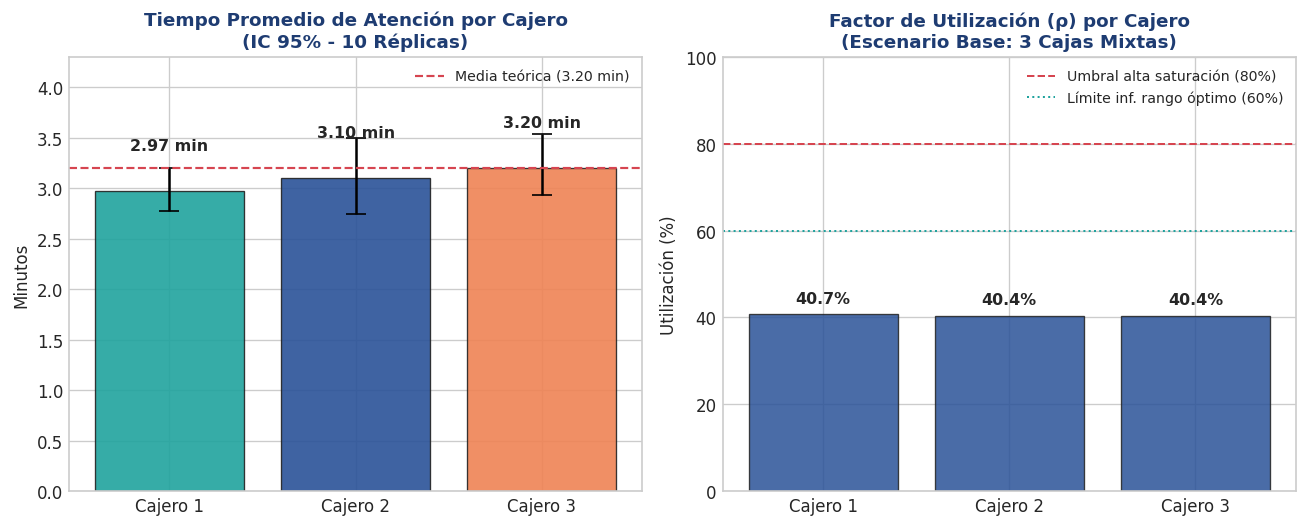

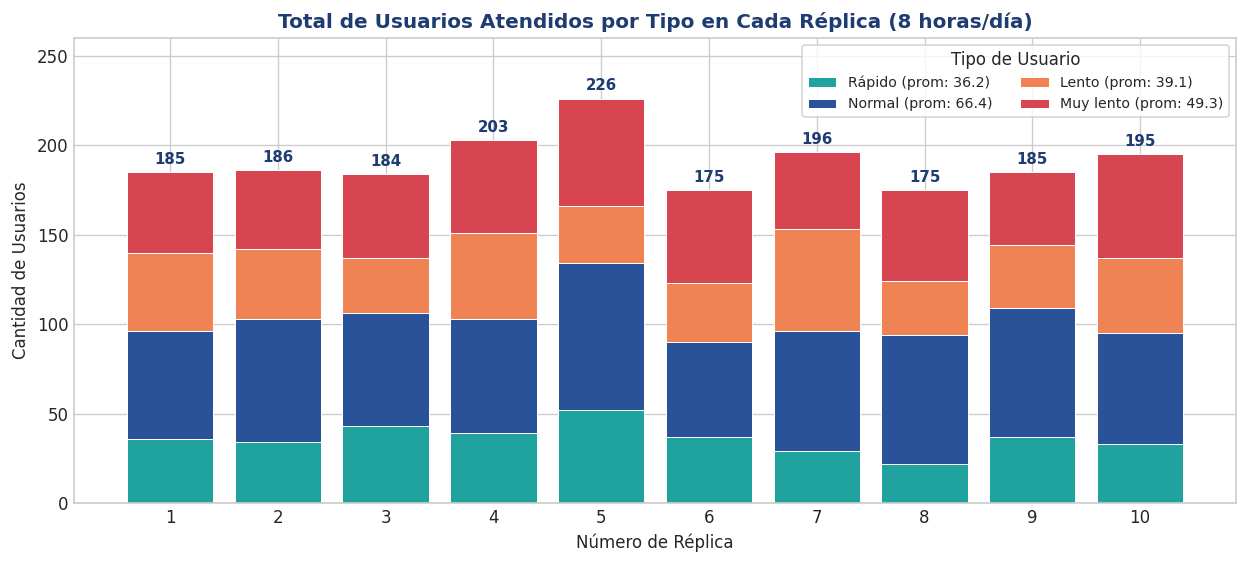

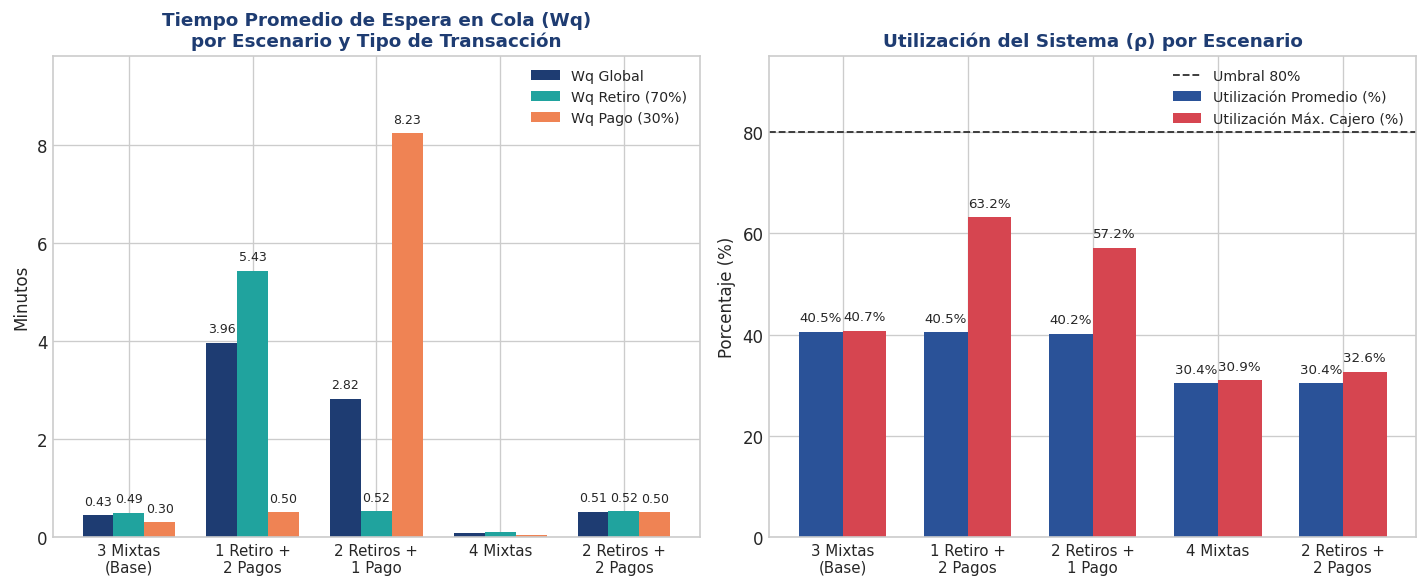

In [ ]:
# Si usas Jupyter Notebook clásico, descomenta la siguiente línea:
# %matplotlib inline

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# Configuración visual para las gráficas en el notebook
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

NAVY  = '#1E3C72'
BLUE  = '#2A5298'
TEAL  = '#20A39E'
AMBER = '#EF8354'
CORAL = '#D64550'


class SimuladorBancoColombia:
    def __init__(self, horas_operacion=8):
        self.tiempo_simulacion = horas_operacion * 60  # 480 minutos
        self.prob_retiro = 0.70
        self.prob_pago = 0.30
        self.tipos_usuario = ['Rápido', 'Normal', 'Lento', 'Muy lento']
        self.prob_usuario = {
            'Retiro': [0.23, 0.40, 0.17, 0.20],
            'Pago':   [0.10, 0.20, 0.30, 0.40]
        }
        self.media_servicio = {
            'Retiro': [1.0, 2.0, 3.0, 4.0],
            'Pago':   [3.0, 3.0, 5.0, 7.0]
        }
        self.media_llegada = {
            'Retiro': [1.0, 2.0, 3.0, 3.0],
            'Pago':   [1.0, 2.0, 3.0, 4.0]
        }

    def generar_llegadas_dia(self, rng):
        llegadas = []
        t = 0.0
        while True:
            accion = 'Retiro' if rng.random() < self.prob_retiro else 'Pago'
            u_idx = rng.choice(4, p=self.prob_usuario[accion])
            dt = rng.exponential(self.media_llegada[accion][u_idx])
            t += dt
            if t > self.tiempo_simulacion:
                break
            ts = rng.exponential(self.media_servicio[accion][u_idx])
            llegadas.append({
                'tiempo_llegada': t,
                'tipo_accion': accion,
                'tipo_usuario': self.tipos_usuario[u_idx],
                'tiempo_servicio': ts
            })
        return llegadas

    def simular_escenario(self, llegadas, configuracion):
        num_cajeros = len(configuracion)
        tiempo_libre = [0.0] * num_cajeros
        tiempo_ocupado_total = [0.0] * num_cajeros
        registros = []

        for cli in llegadas:
            t_lleg = cli['tiempo_llegada']
            accion = cli['tipo_accion']
            ts = cli['tiempo_servicio']
            elegibles = [i for i, tipo in enumerate(configuracion) if tipo == 'Mixto' or tipo == accion]
            mejor_cajero = min(elegibles, key=lambda idx: tiempo_libre[idx])

            inicio = max(t_lleg, tiempo_libre[mejor_cajero])
            espera = inicio - t_lleg
            fin = inicio + ts
            tiempo_libre[mejor_cajero] = fin

            ocup_ini = min(inicio, self.tiempo_simulacion)
            ocup_fin = min(fin, self.tiempo_simulacion)
            if ocup_fin > ocup_ini:
                tiempo_ocupado_total[mejor_cajero] += (ocup_fin - ocup_ini)

            registros.append({
                'cajero': f'Cajero {mejor_cajero + 1}',
                'rol_cajero': configuracion[mejor_cajero],
                'tipo_accion': accion,
                'tipo_usuario': cli['tipo_usuario'],
                'tiempo_llegada': t_lleg,
                'tiempo_espera': espera,
                'tiempo_servicio': ts,
                'tiempo_sistema': espera + ts
            })

        utilizaciones = {
            f'Cajero {i+1}': tiempo_ocupado_total[i] / self.tiempo_simulacion
            for i in range(num_cajeros)
        }
        return pd.DataFrame(registros), utilizaciones


# ==========================================
# 1. EJECUCIÓN DE LAS 10 RÉPLICAS
# ==========================================
sim = SimuladorBancoColombia(horas_operacion=8)
num_replicas = 10

escenarios = {
    'Escenario 1: 3 Mixtas': ['Mixto', 'Mixto', 'Mixto'],
    'Escenario 2: 1 Retiro + 2 Pagos': ['Retiro', 'Pago', 'Pago'],
    'Escenario 3: 2 Retiros + 1 Pago': ['Retiro', 'Retiro', 'Pago'],
    'Escenario 4: 4 Mixtas': ['Mixto', 'Mixto', 'Mixto', 'Mixto'],
    'Escenario 5: 2 Retiros + 2 Pagos': ['Retiro', 'Retiro', 'Pago', 'Pago']
}

resultados_escenarios = {k: [] for k in escenarios}
utilizaciones_escenarios = {k: [] for k in escenarios}

for r in range(1, num_replicas + 1):
    rng = np.random.default_rng(seed=100 + r)
    llegadas = sim.generar_llegadas_dia(rng)
    for nombre, cfg in escenarios.items():
        df_r, util_r = sim.simular_escenario(llegadas, cfg)
        df_r['replica'] = r
        util_r['replica'] = r
        resultados_escenarios[nombre].append(df_r)
        utilizaciones_escenarios[nombre].append(util_r)

dfs = {k: pd.concat(v, ignore_index=True) for k, v in resultados_escenarios.items()}
utils_dfs = {k: pd.DataFrame(v) for k, v in utilizaciones_escenarios.items()}

# ==========================================
# 2. CÁLCULO DE MÉTRICAS PARA LAS GRÁFICAS
# ==========================================
df_base = dfs['Escenario 1: 3 Mixtas']
util_base = utils_dfs['Escenario 1: 3 Mixtas']

# Punto 1: Métricas por cajero (Escenario Base)
p1 = df_base.groupby('cajero').agg(
    servicio_prom=('tiempo_servicio', 'mean'),
    espera_prom=('tiempo_espera', 'mean')
)
ic_inf, ic_sup, util_pct = [], [], []
for caj in p1.index:
    medias_rep = df_base[df_base['cajero'] == caj].groupby('replica')['tiempo_servicio'].mean()
    m = medias_rep.mean()
    h = stats.sem(medias_rep) * stats.t.ppf(0.975, len(medias_rep) - 1)
    ic_inf.append(m - h)
    ic_sup.append(m + h)
    util_pct.append(util_base[caj].mean() * 100)

p1['IC95_inf'] = ic_inf
p1['IC95_sup'] = ic_sup
p1['utilizacion_pct'] = util_pct

# Puntos 2 y 3: Usuarios por tipo y réplica
orden_tipos = ['Rápido', 'Normal', 'Lento', 'Muy lento']
rep_tipo = df_base.groupby(['replica', 'tipo_usuario']).size().unstack(fill_value=0)[orden_tipos]
rep_tipo['Total_Replica'] = rep_tipo.sum(axis=1)

# Puntos 4 y 5: Comparación de escenarios
resumen_esc = []
for nombre, df_e in dfs.items():
    u_df = utils_dfs[nombre].drop(columns=['replica'])
    resumen_esc.append({
        'Escenario': nombre,
        'Wq_Global_min': df_e['tiempo_espera'].mean(),
        'Wq_Retiro_min': df_e[df_e['tipo_accion'] == 'Retiro']['tiempo_espera'].mean(),
        'Wq_Pago_min': df_e[df_e['tipo_accion'] == 'Pago']['tiempo_espera'].mean(),
        'Utilizacion_Prom_pct': u_df.values.mean() * 100,
        'Utilizacion_Max_Caj_pct': u_df.mean().max() * 100
    })
df_comp = pd.DataFrame(resumen_esc)

print("=== RESUMEN DE ESCENARIOS ===")
display(df_comp.round(3))

# ==========================================
# 3. GRÁFICA 1: DESEMPEÑO POR CAJERO (BASE)
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
cajeros = p1.index.tolist()
medias = p1['servicio_prom'].values
err_inf = medias - p1['IC95_inf'].values
err_sup = p1['IC95_sup'].values - medias

bars1 = ax1.bar(cajeros, medias, yerr=[err_inf, err_sup], capsize=6,
                color=[TEAL, BLUE, AMBER], alpha=0.9, edgecolor='#222', linewidth=0.8)
ax1.axhline(3.198, color=CORAL, linestyle='--', linewidth=1.3, label='Media teórica (3.20 min)')
ax1.set_title('Tiempo Promedio de Atención por Cajero\n(IC 95% - 10 Réplicas)', fontsize=11, fontweight='bold', color=NAVY)
ax1.set_ylabel('Minutos')
ax1.set_ylim(0, 4.3)
ax1.legend(loc='upper right', fontsize=8.5)
for bar, val in zip(bars1, medias):
    ax1.text(bar.get_x() + bar.get_width()/2, val + 0.38, f'{val:.2f} min', ha='center', va='bottom', fontsize=9.5, fontweight='bold')

utils_vals = p1['utilizacion_pct'].values
bars2 = ax2.bar(cajeros, utils_vals, color=BLUE, alpha=0.85, edgecolor='#222', linewidth=0.8)
ax2.axhline(80, color=CORAL, linestyle='--', linewidth=1.2, label='Umbral alta saturación (80%)')
ax2.axhline(60, color=TEAL, linestyle=':', linewidth=1.2, label='Límite inf. rango óptimo (60%)')
ax2.set_title('Factor de Utilización (ρ) por Cajero\n(Escenario Base: 3 Cajas Mixtas)', fontsize=11, fontweight='bold', color=NAVY)
ax2.set_ylabel('Utilización (%)')
ax2.set_ylim(0, 100)
ax2.legend(loc='upper right', fontsize=8.5)
for bar, val in zip(bars2, utils_vals):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 2.0, f'{val:.1f}%', ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

# ==========================================
# 4. GRÁFICA 2: USUARIOS POR TIPO Y RÉPLICA
# ==========================================
fig, ax = plt.subplots(figsize=(10.5, 4.8))
replicas_idx = rep_tipo.index.astype(str)
bottom = np.zeros(len(replicas_idx))
paleta_tipos = {'Rápido': TEAL, 'Normal': BLUE, 'Lento': AMBER, 'Muy lento': CORAL}

for tipo in orden_tipos:
    vals = rep_tipo[tipo].values
    ax.bar(replicas_idx, vals, bottom=bottom,
           label=f'{tipo} (prom: {vals.mean():.1f})',
           color=paleta_tipos[tipo], edgecolor='white', linewidth=0.6)
    bottom += vals

for i, tot in enumerate(rep_tipo['Total_Replica'].values):
    ax.text(i, tot + 3, f'{tot}', ha='center', va='bottom', fontsize=9, fontweight='bold', color=NAVY)

ax.set_title('Total de Usuarios Atendidos por Tipo en Cada Réplica (8 horas/día)', fontsize=12, fontweight='bold', color=NAVY)
ax.set_xlabel('Número de Réplica')
ax.set_ylabel('Cantidad de Usuarios')
ax.set_ylim(0, 260)
ax.legend(title='Tipo de Usuario', loc='upper right', ncol=2, fontsize=8.5, frameon=True)
plt.tight_layout()
plt.show()

# ==========================================
# 5. GRÁFICA 3: COMPARACIÓN DE ESCENARIOS
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.0))
etiquetas_cortas = ['3 Mixtas\n(Base)', '1 Retiro +\n2 Pagos', '2 Retiros +\n1 Pago', '4 Mixtas', '2 Retiros +\n2 Pagos']
x = np.arange(len(etiquetas_cortas))
w = 0.25

b1 = ax1.bar(x - w, df_comp['Wq_Global_min'], width=w, label='Wq Global', color=NAVY)
b2 = ax1.bar(x, df_comp['Wq_Retiro_min'], width=w, label='Wq Retiro (70%)', color=TEAL)
b3 = ax1.bar(x + w, df_comp['Wq_Pago_min'], width=w, label='Wq Pago (30%)', color=AMBER)

ax1.set_title('Tiempo Promedio de Espera en Cola (Wq)\npor Escenario y Tipo de Transacción', fontsize=11, fontweight='bold', color=NAVY)
ax1.set_xticks(x)
ax1.set_xticklabels(etiquetas_cortas, fontsize=9)
ax1.set_ylabel('Minutos')
ax1.set_ylim(0, 9.8)
ax1.legend(fontsize=8.5)
for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        if h >= 0.3:
            ax1.text(bar.get_x() + bar.get_width()/2, h + 0.15, f'{h:.2f}', ha='center', va='bottom', fontsize=7.5)

w2 = 0.35
u1 = ax2.bar(x - w2/2, df_comp['Utilizacion_Prom_pct'], width=w2, label='Utilización Promedio (%)', color=BLUE)
u2 = ax2.bar(x + w2/2, df_comp['Utilizacion_Max_Caj_pct'], width=w2, label='Utilización Máx. Cajero (%)', color=CORAL)
ax2.axhline(80, color='#333', linestyle='--', linewidth=1.1, label='Umbral 80%')
ax2.set_title('Utilización del Sistema (ρ) por Escenario', fontsize=11, fontweight='bold', color=NAVY)
ax2.set_xticks(x)
ax2.set_xticklabels(etiquetas_cortas, fontsize=9)
ax2.set_ylabel('Porcentaje (%)')
ax2.set_ylim(0, 95)
ax2.legend(fontsize=8.5)
for bars in [u1, u2]:
    for bar in bars:
        h = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2, h + 1.5, f'{h:.1f}%', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()